# Exercício Prático 2: Sistema Especialista do Século XXI
## Modelo de Classificação de Câncer de Mama com Árvore de Decisão

**Disciplina:** TN724 - Inteligência Artificial 2026.1

**Alunos:** Bruno Lima

**Professor:** Ronaldo e Silva Vieira

## 1. Introdução

Sistemas especialistas são softwares que emulam o conhecimento de um profissional especialista sobre um problema, 
utilizando regras simples. Neste exercício, construímos um "sistema especialista do século XXI", onde em vez de codificar 
manualmente as regras a partir do conhecimento de um especialista, utilizamos **aprendizado supervisionado** (árvore de decisão) 
para descobrir automaticamente as regras de classificação.

O sistema especialista resultante é capaz de classificar tumores de mama como **malignos** ou **benignos** com base em 
características extraídas de imagens digitalizadas de aspirados por agulha fina (FNA) de massas mamárias.

O fluxo do trabalho consiste em:
1. Carregar e preparar o conjunto de dados Breast Cancer do scikit-learn
2. Treinar uma árvore de decisão para classificação
3. Avaliar o modelo com métricas adequadas
4. Traduzir as regras aprendidas para uma base de conhecimento em Prolog

## 2. Importação de Bibliotecas

In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt

# Arquivos de apoio ao README, gerados ao executar o notebook na raiz do projeto
pasta_imagens = Path("images")
pasta_imagens.mkdir(exist_ok=True)


## 3. Escolha e Carregamento do Conjunto de Dados (Passo 1)

O conjunto de dados escolhido foi o **Breast Cancer Wisconsin (Diagnostic)**. 
Ele contém 569 registros com 30 características numéricas extraídas de imagens de FNA de massas mamárias. 
O alvo (`target`) é binário:
- **0** = maligno
- **1** = benigno

As 30 features descrevem propriedades dos núcleos celulares presentes na imagem, como raio, textura, perímetro, 
área, suavidade, compacidade, concavidade, pontos côncavos, simetria e dimensão fractal — cada uma com 
valores de média, erro padrão e pior caso (worst).

In [2]:
# Carregamento do dataset
dataset = load_breast_cancer(as_frame=True)
X = dataset.data
y = dataset.target
df = pd.concat([X, y], axis=1)

print(f'Dimensões do dataset: {df.shape}')
print(f'\nDistribuição das classes:')
print(y.value_counts().rename({0: '0 (maligno)', 1: '1 (benigno)'}))
print(f'\nPrimeiras linhas:')
df.head()

Dimensões do dataset: (569, 31)

Distribuição das classes:
target
1 (benigno)    357
0 (maligno)    212
Name: count, dtype: int64

Primeiras linhas:
Out[2]: 
   mean radius  mean texture  ...  worst fractal dimension  target
0        17.99         10.38  ...                  0.11890       0
1        20.57         17.77  ...                  0.08902       0
2        19.69         21.25  ...                  0.08758       0
3        11.42         20.38  ...                  0.17300       0
4        20.29         14.34  ...                  0.07678       0

[5 rows x 31 columns]


## 4. Pré-processamento: Discretização das Variáveis Numéricas

Como o enunciado recomenda trabalhar com características categóricas, precisamos converter as variáveis numéricas 
em categóricas. Para isso, utilizamos o `KBinsDiscretizer` do scikit-learn com a estratégia `quantile`, 
que divide cada variável em 3 faixas (bins) com aproximadamente o mesmo número de amostras em cada faixa:
- **0** = valor baixo
- **1** = valor médio
- **2** = valor alto

### Regime de separação de dados
Optamos pelo **holdout aleatório estratificado** (80% treino / 20% teste), utilizando o parâmetro `stratify=y` 
para garantir que a proporção de classes seja mantida nos conjuntos de treino e teste.

A discretização é ajustada (`fit`) apenas nos dados de treino e depois aplicada (`transform`) nos dados de teste, 
evitando vazamento de dados (data leakage).
Na validação cruzada, o discretizador também precisa ser ajustado apenas no treino de cada fold. Por isso, colocamos a discretização e a árvore em um `Pipeline`. As faixas são ordinais: a árvore continua fazendo divisões por limiares sobre os valores 0, 1 e 2.


In [3]:
# Separação treino/teste com holdout aleatório estratificado
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# O ajuste da discretização será feito dentro do Pipeline na próxima seção
print(f'Conjunto de treino: {X_train.shape[0]} amostras')
print(f'Conjunto de teste: {X_test.shape[0]} amostras')


Conjunto de treino: 455 amostras
Conjunto de teste: 114 amostras


## 5. Treinamento da Árvore de Decisão (Passo 2)

### Ajuste de hiperparâmetros
Tentativas iniciais de treinar o modelo sem restrições resultaram em **overfitting** (acurácia de ~100% no treino). 
Para controlar a complexidade da árvore e evitar esse problema, utilizamos `GridSearchCV` com validação cruzada 
5-fold para encontrar os melhores valores de `max_depth` e `min_samples_leaf`.
Mantivemos a acurácia como critério de seleção do exercício. O recall da classe maligna será apresentado separadamente, pois a acurácia sozinha não mostra quantos tumores malignos foram classificados como benignos. O conjunto de teste não participa da escolha dos hiperparâmetros.


In [4]:
# Busca dos melhores hiperparâmetros com GridSearchCV
valores_para_testar = {
    'arvore__max_depth': [3, 4, 5, 6],
    'arvore__min_samples_leaf': [5, 10, 15, 20]
}

pipeline = Pipeline([
    ('discretizador', KBinsDiscretizer(
        n_bins=3, encode='ordinal', strategy='quantile',
        quantile_method='linear', subsample=None
    )),
    ('arvore', DecisionTreeClassifier(random_state=42))
])

grid = GridSearchCV(pipeline, valores_para_testar, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

print(f'Melhores hiperparâmetros: {grid.best_params_}')
print(f'Melhor acurácia na validação cruzada: {grid.best_score_*100:.2f}%')


Melhores hiperparâmetros: {'arvore__max_depth': 3, 'arvore__min_samples_leaf': 5}
Melhor acurácia na validação cruzada: 94.51%


In [5]:
# Treinamento do modelo final com os melhores hiperparâmetros
modelo = grid.best_estimator_
# O GridSearchCV já reajustou o melhor Pipeline em todo o treino
clf = modelo.named_steps['arvore']
discretizer = modelo.named_steps['discretizador']
X_train_cat = discretizer.transform(X_train)
X_test_cat = discretizer.transform(X_test)

# Predições no conjunto de teste
y_pred = modelo.predict(X_test)

# Acurácias
acc_treino = accuracy_score(y_train, modelo.predict(X_train))
acc_teste = accuracy_score(y_test, y_pred)

print(f'Acurácia no treino: {acc_treino*100:.2f}%')
print(f'Acurácia no teste:  {acc_teste*100:.2f}%')
print(f'Profundidade da árvore: {clf.get_depth()}')

Acurácia no treino: 96.92%
Acurácia no teste:  91.23%
Profundidade da árvore: 3


## 6. Avaliação do Modelo (Passo 3)

### 6.1 Matriz de Confusão

Matriz de Confusão:
[[38  4]
 [ 6 66]]


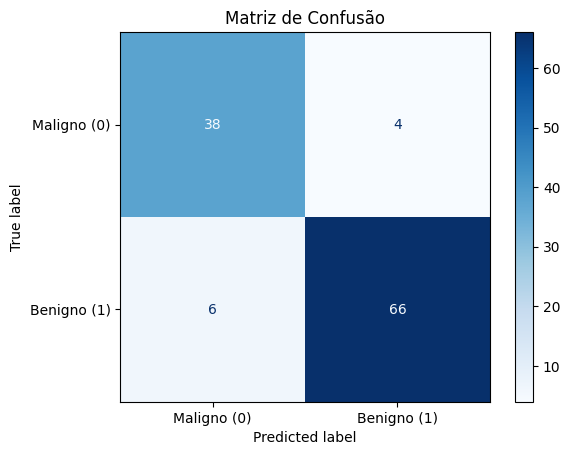

In [6]:
# Matriz de confusão
matrix_confusao = confusion_matrix(y_test, y_pred, labels=[0, 1])
print('Matriz de Confusão:')
print(matrix_confusao)

# Visualização
disp = ConfusionMatrixDisplay(
    confusion_matrix=matrix_confusao,
    display_labels=['Maligno (0)', 'Benigno (1)']
)
disp.plot(cmap=plt.cm.Blues)
plt.title('Matriz de Confusão')
plt.savefig(pasta_imagens / 'matriz_confusao.png', dpi=150, bbox_inches='tight')
plt.show()

### 6.2 Cálculo Manual de Precisão, Recall e F1-Score

As métricas são calculadas manualmente a partir da matriz de confusão, considerando a classe **benigno (1)** como positiva:

- **Precisão** = VP / (VP + FP) — dos que o modelo disse serem benignos, quantos realmente são?
- **Recall** = VP / (VP + FN) — dos tumores realmente benignos, quantos o modelo identificou?
- **F1-Score** = 2 × (Precisão × Recall) / (Precisão + Recall) — média harmônica entre precisão e recall
Também calculamos a **sensibilidade (recall) da classe maligna (0)**: dos tumores realmente malignos, quantos foram identificados? Nesse cálculo, a classe de interesse passa a ser a maligna. Um maligno classificado como benigno é um falso negativo para a classe maligna, embora apareça como FP nas contas acima, que usam benigno como classe positiva.


In [7]:
# Cálculo manual das métricas a partir da matriz de confusão
vn = float(matrix_confusao[0][0])  # Verdadeiros Negativos
fp = float(matrix_confusao[0][1])  # Falsos Positivos
fn = float(matrix_confusao[1][0])  # Falsos Negativos
vp = float(matrix_confusao[1][1])  # Verdadeiros Positivos

precisao = vp / (vp + fp)
recall = vp / (vp + fn)
f1score = 2 * (precisao * recall) / (precisao + recall)
acuracia = (vp + vn) / (vp + vn + fp + fn)

print(f'Verdadeiros Positivos (VP): {vp:.0f}')
print(f'Verdadeiros Negativos (VN): {vn:.0f}')
print(f'Falsos Positivos (FP): {fp:.0f}')
print(f'Falsos Negativos (FN): {fn:.0f}')
print(f'\nPrecisão:  {precisao*100:.2f}%')
print(f'Recall:    {recall*100:.2f}%')
print(f'F1-Score:  {f1score*100:.2f}%')
print(f'Acurácia:  {acuracia*100:.2f}%')
# Recall da classe maligna, mantendo as métricas originais da classe benigna
recall_maligno = matrix_confusao[0, 0] / matrix_confusao[0, :].sum()
print(f'\nSensibilidade / recall (maligno): {recall_maligno*100:.2f}%')
print(f'Malignos classificados como benignos: {matrix_confusao[0, 1]} de {matrix_confusao[0, :].sum()}')


Verdadeiros Positivos (VP): 66
Verdadeiros Negativos (VN): 38
Falsos Positivos (FP): 4
Falsos Negativos (FN): 6

Precisão:  94.29%
Recall:    91.67%
F1-Score:  92.96%
Acurácia:  91.23%

Sensibilidade / recall (maligno): 90.48%
Malignos classificados como benignos: 4 de 42


### 6.3 Visualização da Árvore de Decisão

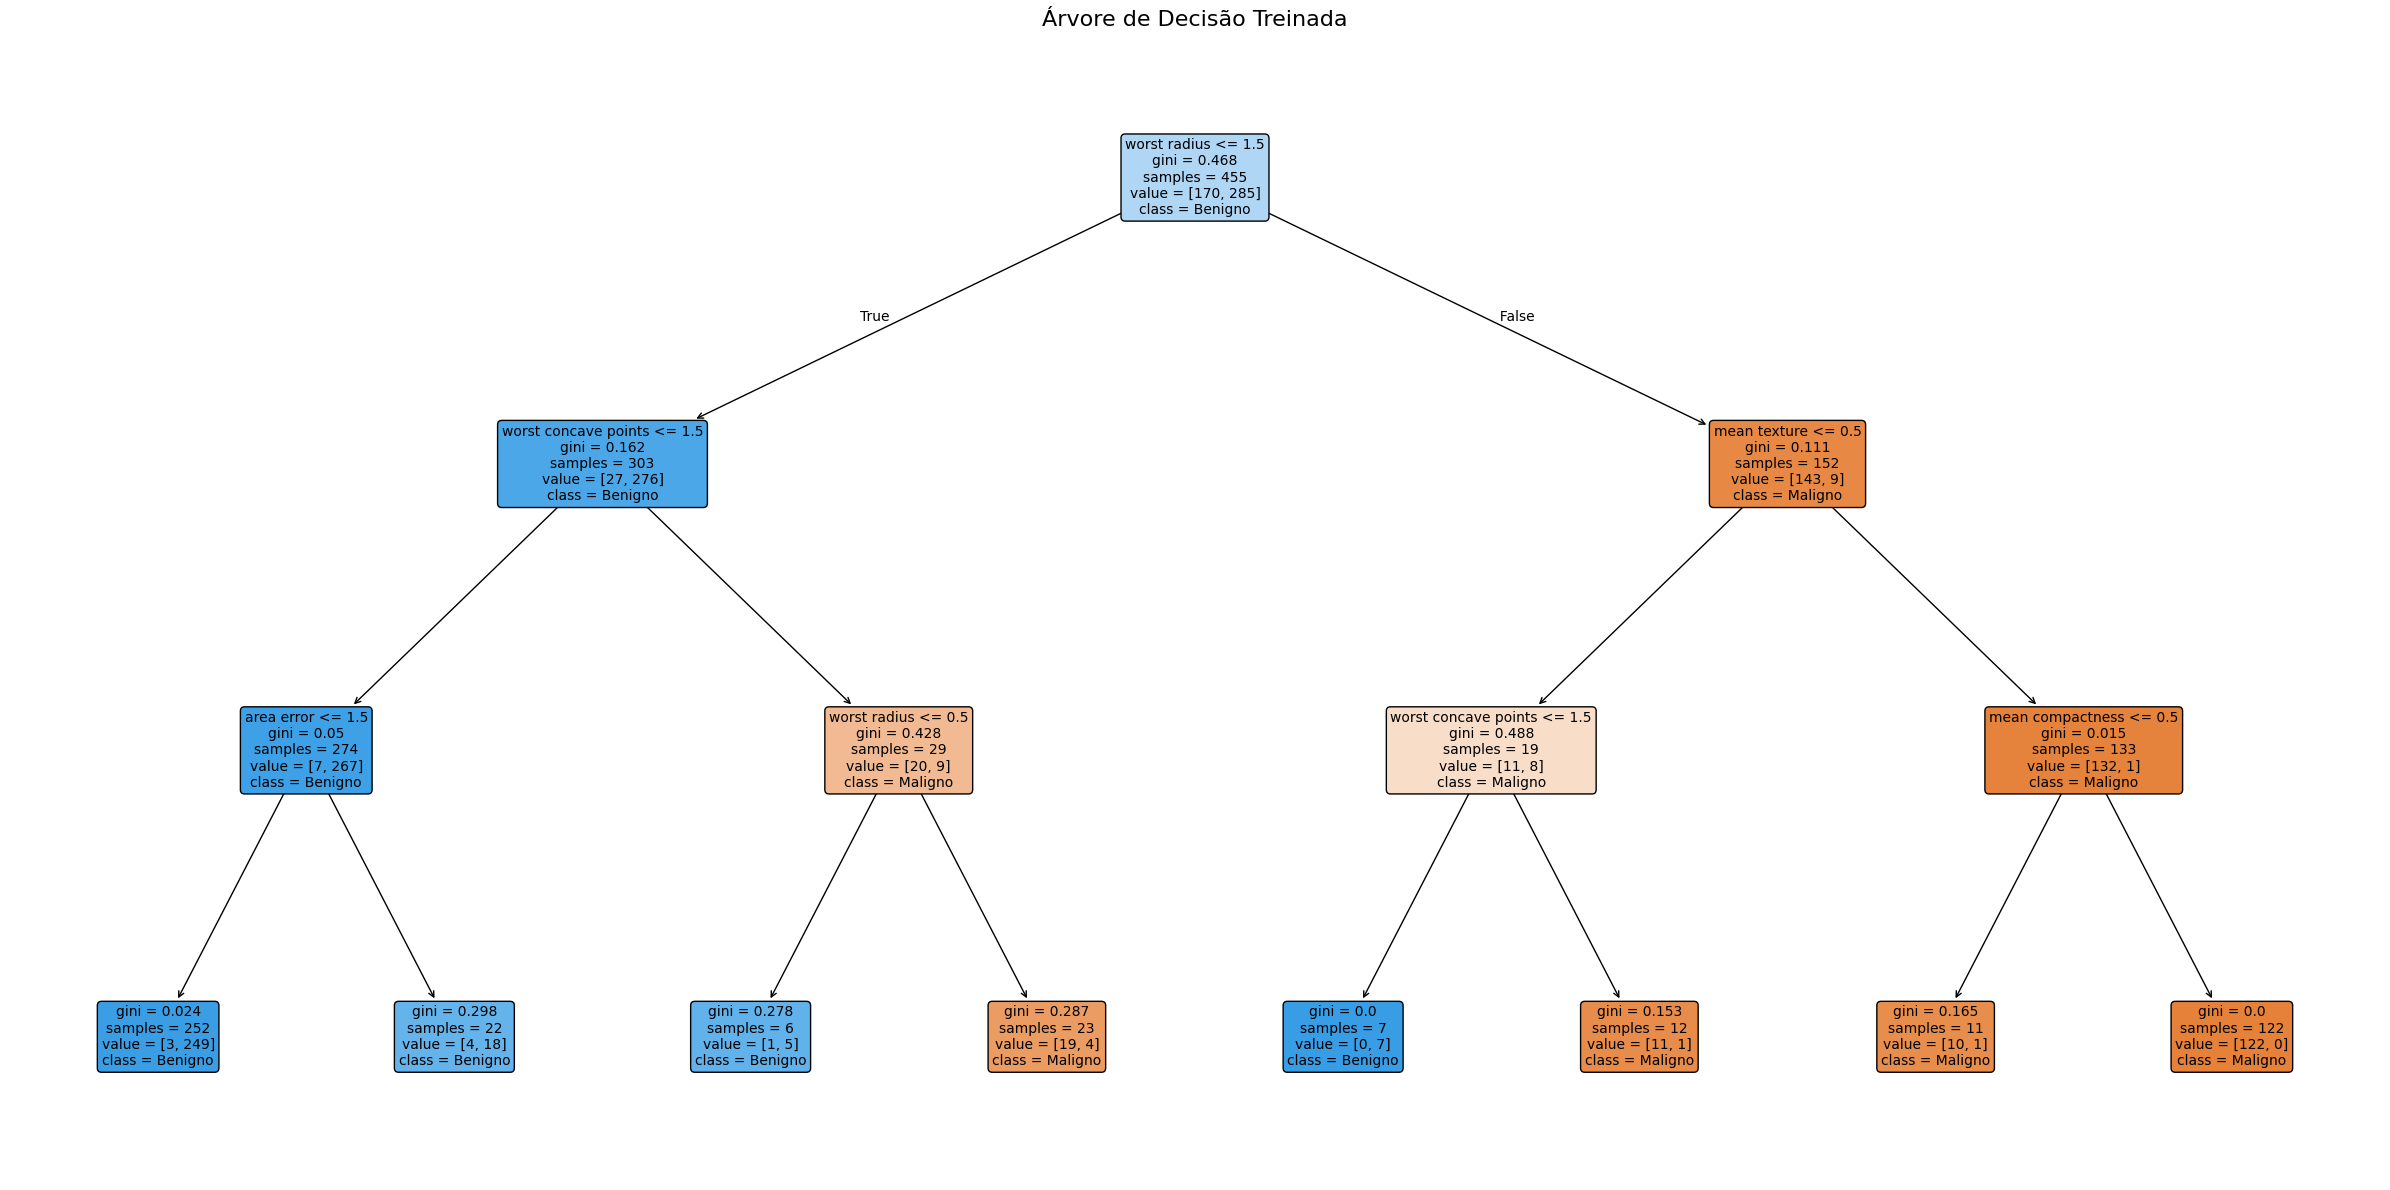

In [8]:
# Visualização gráfica da árvore
plt.figure(figsize=(24, 12))
plot_tree(
    clf,
    feature_names=list(X.columns),
    class_names=['Maligno', 'Benigno'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Árvore de Decisão Treinada', fontsize=16)
plt.tight_layout()
plt.savefig(pasta_imagens / 'arvore_decisao.png', dpi=120, bbox_inches='tight')
plt.show()

In [9]:
# Regras da árvore em formato texto
regras_texto = export_text(clf, feature_names=list(X.columns))
print('Regras da Árvore de Decisão:')
print(regras_texto)

Regras da Árvore de Decisão:
|--- worst radius <= 1.50
|   |--- worst concave points <= 1.50
|   |   |--- area error <= 1.50
|   |   |   |--- class: 1
|   |   |--- area error >  1.50
|   |   |   |--- class: 1
|   |--- worst concave points >  1.50
|   |   |--- worst radius <= 0.50
|   |   |   |--- class: 1
|   |   |--- worst radius >  0.50
|   |   |   |--- class: 0
|--- worst radius >  1.50
|   |--- mean texture <= 0.50
|   |   |--- worst concave points <= 1.50
|   |   |   |--- class: 1
|   |   |--- worst concave points >  1.50
|   |   |   |--- class: 0
|   |--- mean texture >  0.50
|   |   |--- mean compactness <= 0.50
|   |   |   |--- class: 0
|   |   |--- mean compactness >  0.50
|   |   |   |--- class: 0



### 6.4 Importância das Características

In [10]:
# Importância das características usadas pela árvore
importancia = clf.feature_importances_
importancia_df = pd.DataFrame({
    'Atributo': X.columns,
    'Importância': importancia
}).sort_values(by='Importância', ascending=False)

# Mostra apenas as features com importância > 0
features_usadas = importancia_df[importancia_df['Importância'] > 0]
print(f'Features utilizadas pela árvore: {len(features_usadas)} de {len(X.columns)}')
print()
print(features_usadas.to_string(index=False))

Features utilizadas pela árvore: 5 de 30

            Atributo  Importância
        worst radius     0.800691
worst concave points     0.162075
        mean texture     0.030154
          area error     0.006196
    mean compactness     0.000884


### 6.5 Discussão dos Resultados

#### Desempenho do modelo
O modelo de árvore de decisão apresentou resultados satisfatórios na classificação de tumores de mama. 
A acurácia no conjunto de teste resume o desempenho nesta divisão de treino e teste. Sem comparação com outros modelos, não podemos afirmar que ela seja competitiva.

#### Análise das métricas
- **Precisão alta** indica que quando o modelo classifica um tumor como benigno, ele geralmente está correto, 
minimizando falsos positivos.
- **Recall alto** indica que o modelo consegue identificar a maioria dos tumores benignos, minimizando falsos negativos.
- O **F1-Score** combina ambas as métricas, fornecendo uma visão equilibrada do desempenho.

#### Regras aprendidas
A árvore de decisão aprendeu regras baseadas principalmente nas características mais discriminativas do dataset. 
As características efetivamente utilizadas e suas importâncias estão na tabela acima. Essa importância descreve as divisões desta árvore; não demonstra causalidade nem relevância clínica por si só.

#### Underfitting vs. Overfitting
- Sem restrição de profundidade, a árvore sofria de **overfitting** (100% de acurácia no treino, menor no teste).
- Com o uso de `max_depth` e `min_samples_leaf` ajustados via `GridSearchCV`, conseguimos controlar a complexidade 
do modelo. A acurácia foi de 96,92% no treino e 91,23% no teste, uma diferença de 5,69 pontos percentuais, mas isso, isoladamente, não garante ausência de overfitting. Os resultados dependem da divisão dos dados e das opções testadas.

#### Qualidade das características
O dataset Breast Cancer possui características de alta qualidade para a tarefa de classificação. 
Mesmo após a discretização em apenas 3 faixas (baixo, médio, alto), a árvore de decisão conseguiu manter 
um bom desempenho, o que demonstra que as features possuem forte poder discriminativo. 
Nota-se que a árvore não utiliza todas as 30 features — apenas um subconjunto reduzido é suficiente para 
realizar a classificação com boa acurácia, o que não prova, por si só, que as demais variáveis sejam redundantes.

#### Dificuldade do problema
O problema de classificação é de dificuldade moderada. O dataset é relativamente bem balanceado 
(~63% benignos, ~37% malignos) e as features possuem boa separabilidade entre as classes. 
A árvore de decisão, mesmo com profundidade limitada, é capaz de capturar os padrões principais do problema.
#### Erros e limitações
O recall da classe maligna merece atenção especial: ele mostra a proporção de tumores malignos identificados, enquanto a acurácia considera os acertos das duas classes. Mesmo com uma acurácia alta, podem ocorrer classificações de malignos como benignos. As contagens desses erros estão na matriz e na célula de métricas.

Trabalhamos com 569 amostras de um único conjunto de dados e uma única separação de teste. A discretização facilita a representação das regras, mas perde informação numérica. Não fizemos validação externa nem avaliação em uso clínico. Este é um projeto acadêmico e de portfólio, não uma ferramenta de diagnóstico e não deve orientar decisões médicas.


## 7. Base de Conhecimento em Prolog (Passo 4)

Nesta seção, traduzimos as regras aprendidas pela árvore de decisão em uma base de conhecimento em Prolog. 
Cada caminho da raiz até uma folha da árvore se torna uma regra Prolog.

Como a árvore utiliza dados discretizados em 3 faixas (0=baixo, 1=médio, 2=alto), os valores dos atributos 
nas regras Prolog representam essas faixas.

### Geração automática das regras
O código a seguir percorre a árvore treinada e gera automaticamente as regras Prolog equivalentes:

In [11]:
def gerar_prolog(clf, feature_names, class_names):
    """Gera base de conhecimento Prolog a partir da árvore de decisão."""
    tree = clf.tree_
    # Identifica quais features são usadas pela árvore
    features_usadas_idx = sorted(set(
        tree.feature[i] for i in range(tree.node_count) if tree.feature[i] >= 0
    ))

    # Mapeamento: índice da feature -> nome do parâmetro Prolog (minúsculo, com _)
    param_map = {}
    for idx in features_usadas_idx:
        nome = feature_names[idx].replace(' ', '_').lower()
        param_map[idx] = nome

    params_prolog = [param_map[i] for i in features_usadas_idx]

    # Coletar todos os caminhos (folhas) da árvore
    caminhos = []

    def percorrer(node_id, condicoes):
        """Percorre a árvore recursivamente coletando condições."""
        if tree.children_left[node_id] == tree.children_right[node_id]:
            # Nó folha
            classe_idx = tree.value[node_id].argmax()
            classe_nome = int(class_names[classe_idx])
            caminhos.append((list(condicoes), classe_nome))
            return

        feat = tree.feature[node_id]
        threshold = tree.threshold[node_id]
        percorrer(tree.children_left[node_id], condicoes + [(feat, '<=', threshold)])
        percorrer(tree.children_right[node_id], condicoes + [(feat, '>', threshold)])

    percorrer(0, [])

    # Simplificar: agrupar caminhos adjacentes com mesma classe e que diferem
    # apenas na última condição (irmãos na árvore com mesma classe)
    simplificados = []
    i = 0
    while i < len(caminhos):
        conds_i, classe_i = caminhos[i]
        # Verificar se o próximo caminho é irmão com mesma classe
        if i + 1 < len(caminhos):
            conds_j, classe_j = caminhos[i + 1]
            if (classe_i == classe_j and
                len(conds_i) == len(conds_j) and
                conds_i[:-1] == conds_j[:-1]):
                # Irmãos com mesma classe: usar apenas as condições em comum
                simplificados.append((conds_i[:-1], classe_i))
                i += 2
                continue
        simplificados.append((conds_i, classe_i))
        i += 1

    # Gerar regras Prolog
    linhas = []
    linhas.append('% Base de Conhecimento - Classificação de Câncer de Mama')
    linhas.append('% Gerada automaticamente a partir de árvore de decisão')
    linhas.append('% Classes: 0 = maligno, 1 = benigno')
    linhas.append('% Valores dos atributos: 0 = baixo, 1 = medio, 2 = alto')
    linhas.append('%')
    linhas.append('% Features utilizadas:')
    for idx in features_usadas_idx:
        linhas.append(f'%   {param_map[idx]} -> {feature_names[idx]}')
    linhas.append(f'%')
    linhas.append(f'% Assinatura: classificar({", ".join(params_prolog)}, Classe)')
    linhas.append('')

    for conds, classe in simplificados:
        # Montar argumentos: variável (maiúscula) se usada, _ se não
        features_no_caminho = {c[0] for c in conds}
        args = []
        for idx in features_usadas_idx:
            if idx in features_no_caminho:
                # Primeira letra maiúscula para variável Prolog
                nome = param_map[idx]
                var = nome[0].upper() + nome[1:]
                args.append(var)
            else:
                args.append('_')
        args.append(str(classe))

        # Montar condições
        conds_prolog = []
        for feat_idx, op, threshold in conds:
            nome = param_map[feat_idx]
            var = nome[0].upper() + nome[1:]
            th_int = int(threshold)
            if op == '<=':
                conds_prolog.append(f'{var} =< {th_int}')
            else:
                conds_prolog.append(f'{var} > {th_int}')

        head = f'classificar({", ".join(args)})'
        if conds_prolog:
            body = ',\n    '.join(conds_prolog)
            linhas.append(f'{head} :-\n    {body}.')
        else:
            linhas.append(f'{head}.')
        linhas.append('')

    return '\n'.join(linhas), features_usadas_idx, params_prolog

# Gerar o código Prolog
class_names_str = [str(c) for c in clf.classes_]
prolog_code, features_idx_usadas, params_prolog = gerar_prolog(clf, list(X.columns), class_names_str)

print(prolog_code)

% Base de Conhecimento - Classificação de Câncer de Mama
% Gerada automaticamente a partir de árvore de decisão
% Classes: 0 = maligno, 1 = benigno
% Valores dos atributos: 0 = baixo, 1 = medio, 2 = alto
%
% Features utilizadas:
%   mean_texture -> mean texture
%   mean_compactness -> mean compactness
%   area_error -> area error
%   worst_radius -> worst radius
%   worst_concave_points -> worst concave points
%
% Assinatura: classificar(mean_texture, mean_compactness, area_error, worst_radius, worst_concave_points, Classe)

classificar(_, _, _, Worst_radius, Worst_concave_points, 1) :-
    Worst_radius =< 1,
    Worst_concave_points =< 1.

classificar(_, _, _, Worst_radius, Worst_concave_points, 1) :-
    Worst_radius =< 1,
    Worst_concave_points > 1,
    Worst_radius =< 0.

classificar(_, _, _, Worst_radius, Worst_concave_points, 0) :-
    Worst_radius =< 1,
    Worst_concave_points > 1,
    Worst_radius > 0.

classificar(Mean_texture, _, _, Worst_radius, Worst_concave_points, 1) :

### Base de Conhecimento Prolog Completa

A saída da célula acima contém a base completa gerada a partir do modelo desta execução. Evitamos repetir as regras manualmente aqui, para que elas não fiquem diferentes da árvore treinada.

Cada regra corresponde a um caminho até uma folha, com simplificação de folhas irmãs da mesma classe. As variáveis não utilizadas são representadas por `_`; as demais começam com letra maiúscula. As regras aceitam os valores discretizados (0, 1 e 2), não as medidas originais.

**Limitação da validação:** as regras não foram executadas em um interpretador Prolog neste projeto. A próxima seção apenas percorre a árvore em Python. Por isso, não incluímos um arquivo `.pl` apresentado como validado. A saída acima pode ser copiada para um interpretador para uma verificação futura.


### Simulação com 5 Exemplos Aleatórios em Python

Selecionamos 5 exemplos aleatórios do conjunto de teste e comparamos o percurso manual da árvore com `predict`. Essa verificação ajuda a acompanhar as decisões, mas não testa a sintaxe nem a execução das regras geradas em Prolog.


In [12]:
def percorrer_arvore_manual(exemplo, clf, features_idx_usadas):
    """Percorre a árvore em Python; não executa o código Prolog gerado."""
    tree = clf.tree_
    node = 0
    caminho = []

    while tree.children_left[node] != tree.children_right[node]:
        feat = tree.feature[node]
        threshold = tree.threshold[node]
        feat_name = list(X.columns)[feat]
        valor = exemplo[feat]

        if valor <= threshold:
            caminho.append(f'{feat_name} = {valor:.0f} <= {threshold:.1f} -> esquerda')
            node = tree.children_left[node]
        else:
            caminho.append(f'{feat_name} = {valor:.0f} > {threshold:.1f} -> direita')
            node = tree.children_right[node]

    classe = int(clf.classes_[tree.value[node].argmax()])
    return classe, caminho


# Selecionar 5 exemplos aleatórios do conjunto de teste
np.random.seed(42)
indices_aleatorios = np.random.choice(len(X_test_cat), size=5, replace=False)

print('=' * 80)
print('VERIFICAÇÃO: 5 Exemplos Aleatórios do Conjunto de Teste')
print('=' * 80)

for i, idx in enumerate(indices_aleatorios):
    exemplo = X_test_cat[idx]
    classe_arvore = int(y_pred[idx])
    classe_real = int(y_test.iloc[idx])
    classe_manual, caminho = percorrer_arvore_manual(exemplo, clf, features_idx_usadas)

    classe_nome = {0: 'maligno', 1: 'benigno'}

    print(f'\nExemplo {i+1} (índice {idx}):')
    print(f'  Valores discretizados das features usadas:')
    for fi in features_idx_usadas:
        print(f'    {X.columns[fi]}: {exemplo[fi]:.0f}')
    print(f'  Caminho na árvore:')
    for passo in caminho:
        print(f'    {passo}')
    print(f'  Classe real:              {classe_real} ({classe_nome[classe_real]})')
    print(f'  Classificação da árvore:  {classe_arvore} ({classe_nome[classe_arvore]})')
    print(f'  Percurso manual (Python):  {classe_manual} ({classe_nome[classe_manual]})')
    print(f'  Coincide? {"SIM" if classe_arvore == classe_manual else "NAO"}')

VERIFICAÇÃO: 5 Exemplos Aleatórios do Conjunto de Teste

Exemplo 1 (índice 80):
  Valores discretizados das features usadas:
    mean texture: 1
    mean compactness: 1
    area error: 1
    worst radius: 1
    worst concave points: 1
  Caminho na árvore:
    worst radius = 1 <= 1.5 -> esquerda
    worst concave points = 1 <= 1.5 -> esquerda
    area error = 1 <= 1.5 -> esquerda
  Classe real:              1 (benigno)
  Classificação da árvore:  1 (benigno)
  Percurso manual (Python):  1 (benigno)
  Coincide? SIM

Exemplo 2 (índice 4):
  Valores discretizados das features usadas:
    mean texture: 2
    mean compactness: 2
    area error: 2
    worst radius: 2
    worst concave points: 2
  Caminho na árvore:
    worst radius = 2 > 1.5 -> direita
    mean texture = 2 > 0.5 -> direita
    mean compactness = 2 > 0.5 -> direita
  Classe real:              0 (maligno)
  Classificação da árvore:  0 (maligno)
  Percurso manual (Python):  0 (maligno)
  Coincide? SIM

Exemplo 3 (índice 40):
  V

In [13]:
# Gerar as consultas Prolog equivalentes para os 5 exemplos
print('Consultas Prolog sugeridas (não executadas):')
print('=' * 80)

for i, idx in enumerate(indices_aleatorios):
    exemplo = X_test_cat[idx]
    classe_arvore = int(y_pred[idx])
    classe_nome = {0: 'maligno', 1: 'benigno'}

    # Montar a consulta
    args = [str(int(exemplo[fi])) for fi in features_idx_usadas]
    args.append('Y')
    consulta = f'classificar({", ".join(args)})'

    print(f'\nExemplo {i+1}:')
    print(f'  ?- {consulta}.')
    print(f'  Resultado esperado: Y = {classe_arvore} ({classe_nome[classe_arvore]})')

Consultas Prolog sugeridas (não executadas):

Exemplo 1:
  ?- classificar(1, 1, 1, 1, 1, Y).
  Resultado esperado: Y = 1 (benigno)

Exemplo 2:
  ?- classificar(2, 2, 2, 2, 2, Y).
  Resultado esperado: Y = 0 (maligno)

Exemplo 3:
  ?- classificar(1, 0, 1, 0, 0, Y).
  Resultado esperado: Y = 1 (benigno)

Exemplo 4:
  ?- classificar(1, 2, 0, 1, 1, Y).
  Resultado esperado: Y = 1 (benigno)

Exemplo 5:
  ?- classificar(0, 1, 0, 1, 1, Y).
  Resultado esperado: Y = 1 (benigno)


## 8. Conclusão

Neste exercício, construímos um sistema especialista moderno para classificação de câncer de mama utilizando 
aprendizado supervisionado com árvore de decisão. O processo envolveu:

1. **Escolha do dataset**: Breast Cancer Wisconsin, com 569 amostras e 30 características numéricas.
2. **Pré-processamento**: Discretização das variáveis numéricas em 3 faixas categóricas usando `KBinsDiscretizer`.
3. **Treinamento**: Árvore de decisão com hiperparâmetros otimizados via `GridSearchCV` para controlar a complexidade.
4. **Avaliação**: Cálculo manual de precisão, recall e F1-score a partir da matriz de confusão, com resultados satisfatórios.
5. **Tradução para Prolog**: Geração automática de uma base de conhecimento em Prolog com regras equivalentes 
às da árvore de decisão. O percurso da árvore foi comparado com `predict` em 5 exemplos aleatórios em Python; o código Prolog não foi executado em um interpretador.

O sistema demonstra como técnicas modernas de aprendizado de máquina podem ser utilizadas para automatizar 
a aquisição de conhecimento que, nos sistemas especialistas clássicos, dependia exclusivamente de profissionais da área.
Este trabalho tem finalidade acadêmica e não foi validado para uso clínico.

### Transparência sobre o uso de IA
O GPT foi usado para formatar, corrgir erros de gramática e melhorar a clareza da comunicação, além de avaliar possíveis erros metodológicos. A estrutura, as decisões tomadas e a forma de comunicação do notebook original foram preservadas sempre que possível.
